# RakshPulse: Complete ML Implementation

This notebook runs the complete RakshPulse blood-pressure ML workflow step by step. It calls **the same functions**
as `python scripts/run_complete_pipeline.py` (`rakshpulse.ml`, the production feature extractor and the production
inference engine), so its numbers are identical to the pipeline's report (`reports/final_model_evaluation.md`).
Section 20 checks this: its models reproduce the exported bundle's predictions exactly.

> **Offline validation only.** The data is the public Auricle dataset (earlobe PPG, Nonin transmissive sensor, CNAP
> continuous BP, healthy adults). Nothing here validates MAX30102 hardware; no MAX30102 recordings with reference BP
> exist yet. RakshPulse is a research prototype, not a medical device.

Run from the repository root's `notebooks/` folder after `pip install -e ".[notebook]"`. Training takes about a
minute on a laptop CPU. Section 4 downloads the raw waveform arrays (about 350 MB) if they are not present.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from rakshpulse.ml import (DatasetPaths, PipelineConfig, audit_datasets, build_ear_dataset, candidate_features,
                           export_bundle, run_training)
from rakshpulse.ml import report as R
from rakshpulse.ml.dataset import feature_reproducibility, validate_auricle
from rakshpulse.ml.training import make_pipeline, metrics, select_features, split_subjects
from rakshpulse.features.feature_pipeline import extract_features, preprocess_channel
from rakshpulse.inference.api import ANALOG_INPUT, BPEstimator, StreamingBPEstimator
from rakshpulse.inference.model_loader import load_bundle

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)
paths = DatasetPaths()                     # repository root is found from the installed package
OUT = paths.root / "reports" / "notebook"  # figures written by this notebook
OUT.mkdir(parents=True, exist_ok=True)
SEED = 0
print("repository:", paths.root)

repository: C:\rakshpukse


## 1. Dataset loading
Audit every dataset folder, then load the standardised Auricle tables.

In [2]:
audit = audit_datasets(paths)
display(audit[["dataset", "file", "status", "rows", "subjects", "labelled_rows"]])
windows = pd.read_csv(paths.auricle / "windows.csv", low_memory=False)
features = pd.read_csv(paths.auricle / "features.csv", low_memory=False)
subjects = pd.read_csv(paths.auricle / "subjects.csv")
print(f"windows {windows.shape}, features {features.shape}, subjects {subjects.shape}")

,dataset,file,status,rows,subjects,labelled_rows
0,auricle,data/auricle/feature_schema.csv,ok,100.0,NaN,NaN
1,auricle,data/auricle/feature_schema_advanced.csv,ok,23.0,NaN,NaN
2,auricle,data/auricle/features.csv,ok,30841.0,42.0,NaN
3,auricle,data/auricle/features_advanced.csv,ok,30841.0,42.0,NaN
4,auricle,data/auricle/features_physio.csv,ok,30841.0,NaN,NaN
5,auricle,data/auricle/recordings.csv,ok,79.0,42.0,NaN
6,auricle,data/auricle/release_manifest.csv,ok,167.0,NaN,NaN
7,auricle,data/auricle/subjects.csv,ok,42.0,42.0,NaN
8,auricle,data/auricle/summary.csv,ok,45.0,NaN,NaN
9,auricle,data/auricle/validation_report.csv,ok,20.0,NaN,NaN


windows (30841, 41), features (30841, 104), subjects (42, 19)


## 2. Dataset inspection
Integrity checks, then the structure of the raw window table.

In [3]:
display(validate_auricle(paths))
print(windows.groupby("session").agg(windows=("window_id", "size"), subjects=("subject_id", "nunique")))
print(windows.label_status.value_counts())
display(windows[["window_id", "subject_id", "session", "t_start_s", "activity_name", "label_valid", "sbp_mmHg",
                 "dbp_mmHg", "ear_sqi_ok", "ear_hr_bpm"]].head())

,check,status,detail
0,window ids unique,PASS,30841 windows
1,features match windows one-to-one,PASS,30841 feature rows
2,subject and session agree between tables,PASS,
3,every subject documented,PASS,42 subjects
4,sessions are 1 or 2,PASS,"[1, 2]"
5,one source sampling rate,PASS,1000 Hz
6,all windows 10 s long,PASS,
7,labels numeric where valid,PASS,16419 labelled
8,SBP > DBP where valid,PASS,
9,raw recordings verified against PhysioNet SHA-256,PASS,79 recordings


         windows  subjects
session                   
1          16057        42
2          14784        37
label_status
ok                 16419
cnap_unreliable    13983
no_cnap_mask         383
implausible_bp        56
Name: count, dtype: int64


,window_id,subject_id,session,t_start_s,activity_name,label_valid,sbp_mmHg,dbp_mmHg,ear_sqi_ok,ear_hr_bpm
0,HC_10_1_w0000,auricle_HC_10,1,0.0,not_applicable,False,NaN,NaN,False,43.80
1,HC_10_1_w0001,auricle_HC_10,1,5.0,not_applicable,False,NaN,NaN,False,113.21
2,HC_10_1_w0002,auricle_HC_10,1,10.0,not_applicable,False,NaN,NaN,False,121.21
3,HC_10_1_w0003,auricle_HC_10,1,15.0,not_applicable,False,NaN,NaN,False,141.18
4,HC_10_1_w0004,auricle_HC_10,1,20.0,not_applicable,False,NaN,NaN,False,28.24


## 3. Missing-value analysis

In [4]:
from rakshpulse.evaluation.auricle_study import add_normalised_shape
add_normalised_shape(features, "ear")          # beat-duration-normalised shape features, as at inference time
cand = candidate_features()
miss = features[cand].isna().mean().sort_values(ascending=False)
labels_missing = windows[["sbp_mmHg", "dbp_mmHg"]].isna().mean()
print("labels missing (fraction of all windows):", labels_missing.round(3).to_dict())
fig, ax = plt.subplots(figsize=(12, 3))
miss.head(25).plot.bar(ax=ax, color="#0F8B8D")
ax.set(title="Most-missing candidate features (all windows, before cleaning)", ylabel="fraction missing")
plt.show()

labels missing (fraction of all windows): {'sbp_mmHg': 0.468, 'dbp_mmHg': 0.468}


## 4. PPG visualisation
Raw earlobe PPG from the published waveform arrays (downloaded from the GitHub release if missing).

In [5]:
npz_path = paths.auricle / "waveforms" / "auricle_waveforms_session1.npz"
if not npz_path.exists():
    from rakshpulse.data.release import fetch
    fetch("waveforms")
wav = np.load(npz_path, allow_pickle=False)
ids = wav["window_id"]
w1 = windows[windows.session == 1].set_index("window_id").reindex(ids)
good = np.flatnonzero(w1.ear_sqi_ok.fillna(False).to_numpy(bool) & w1.label_valid.fillna(False).to_numpy(bool))
i = int(good[len(good) // 2])
raw = wav["raw_ear"][i].astype(float)
fs = 100.0  # the published arrays are stored at 100 Hz
t = np.arange(raw.size) / fs
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, raw, color="#1B2A4A", lw=0.8)
ax.set(title=f"Raw earlobe PPG, window {ids[i]} (CNAP SBP {w1.iloc[i].sbp_mmHg:.0f} / DBP {w1.iloc[i].dbp_mmHg:.0f} mmHg)",
       xlabel="s", ylabel="mV")
plt.show()

## 5. Signal preprocessing
The production chain: DC removal, resampling to 100 Hz, despiking, 0.5–10 Hz band-pass, orientation, beat segmentation and the quality gate.

In [6]:
pc = preprocess_channel(raw, fs, has_dc=False)
print("quality gate acceptable:", pc.sqi.acceptable, "| reasons:", pc.sqi.reasons or "none",
      f"| beats {pc.sqi.n_beats}, template correlation {pc.sqi.template_corr:.2f}")
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(pc.filtered.size) / 100, pc.filtered, color="#0F8B8D", lw=0.9)
from rakshpulse.preprocessing.segmentation import detect_feet, detect_peaks
for foot in detect_feet(pc.filtered, detect_peaks(pc.filtered, 100.0)):
    ax.axvline(foot / 100, color="#D9731A", lw=0.6, alpha=0.7)
print(f"{len(pc.beats)} beats kept after outlier-beat rejection")
ax.set(title="Preprocessed (band-passed, z-scored) PPG with detected beat onsets", xlabel="s", ylabel="z")
plt.show()

quality gate acceptable: True | reasons: none | beats 11, template correlation 0.99
11 beats kept after outlier-beat rejection


## 6. Signal normalisation
Each window is z-scored by the preprocessing (above). Features are winsorised, imputed and standardised inside each model pipeline, fitted on training subjects only.

In [7]:
print(f"preprocessed window: mean {pc.filtered.mean():.3f}, SD {pc.filtered.std():.3f}")
d, cleaning_log = build_ear_dataset(paths)
train_s, test_s = split_subjects(d, 0.2, SEED)
train = d[d.subject_id.isin(train_s) & d.fit_window]
pipe = make_pipeline("ridge", SEED)
Xs = pipe[:-1].fit_transform(train[cand].to_numpy(float))   # clip -> impute -> scale, fitted on training rows
print("standardised training features: mean", np.round(np.nanmean(Xs, axis=0)[:5], 3), "SD", np.round(Xs.std(axis=0)[:5], 3))

preprocessed window: mean 0.000, SD 1.000


standardised training features: mean [-0. -0. -0.  0.  0.] SD [1. 1. 1. 1. 1.]


## 7. Feature extraction
The production extractor on the raw window, compared with the stored features, and on 200 random windows.

In [8]:
f_now, _ = extract_features({"ir": raw}, fs, has_dc=False)
stored = features.set_index("window_id").loc[ids[i]]
cmp = pd.DataFrame({"recomputed": {f"ear_{k[3:]}": v for k, v in f_now.items() if k.startswith("ir_")}})
cmp["stored"] = [stored.get(k, np.nan) for k in cmp.index]
display(cmp.loc[[c for c in cmp.index if c in cand]].head(12).round(4))
rep = feature_reproducibility(paths, n=200)
print(f"median Spearman agreement over {int(rep.n_windows.max())} windows: {rep.spearman.median():.4f}")

,recomputed,stored
ear_beat_T,0.8700,0.8700
ear_sys_T,0.1900,0.1900
ear_dia_T,0.6800,0.6800
ear_sys_ratio,0.2184,0.2184
ear_w10,0.6400,0.6400
ear_w25,0.5300,0.5300
ear_w50,0.3800,0.3800
ear_w75,0.2100,0.2100
ear_w90,0.1300,0.1300
ear_w10_sd_ratio,2.5000,2.5000


median Spearman agreement over 200 windows: 0.9988


## 8. Feature selection
On training subjects only: drop features missing in more than 20 % of windows, constant features, and the later feature of each pair with |Spearman ρ| > 0.95.

In [9]:
sel = select_features(d[d.subject_id.isin(train_s)], cand, 0.2, 0.95)
print(f"{sel.selected.sum()} of {len(sel)} candidate features selected")
display(sel[~sel.selected])

40 of 47 candidate features selected


,feature,missing_rate,selected,reason
9,ear_beat_T,0.0,False,|rho|=0.996 with ear_hr
14,ear_w25,0.0,False,|rho|=0.971 with ear_w10
19,ear_w25_sd_ratio,0.0,False,|rho|=0.968 with ear_w10_sd_ratio
23,ear_area_sys,0.0,False,|rho|=0.979 with ear_sys_T
28,ear_beat_skew,0.0,False,|rho|=0.957 with ear_w50_n
40,ear_f0,0.0,False,|rho|=0.957 with ear_hr
45,ear_pow_2_5,0.0,False,|rho|=0.998 with ear_pow_0p5_2


## 9. SBP/DBP label preparation
Labels are the CNAP SBP/DBP of each 10 s window. The cleaning removes unreliable, implausible and misaligned labels.

In [10]:
display(cleaning_log)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for a, col, c in zip(ax, ("sbp", "dbp"), ("#1B2A4A", "#0F8B8D")):
    a.hist(d[col], bins=40, color=c)
    a.set(title=f"{col.upper()} labels after cleaning", xlabel="mmHg")
plt.show()
print(d[["sbp", "dbp"]].describe().round(1))

,step,filter,rule,windows,subjects,records
0,0,all windows,"standardised Auricle windows (10 s, 5 s hop)",30841,42,79
1,1,reliable CNAP label,"label_valid (CNAP mask valid, label_status ok)",16419,42,78
2,2,plausible BP,"SBP (60.0, 250.0), DBP (30.0, 150.0), pulse pr...",16369,42,78
3,3,label aligned,SBP range inside the window <= 20.0 mmHg,12743,42,78
4,4,ear signal quality,"production SQI gate passed (beats, HR, regular...",9851,40,72
5,5,no saturation,rail-clipped samples <= 1.0 %,9851,40,72
6,6,core features present,heart rate and beat duration extracted,9851,40,72
7,7,enough windows per subject,>= 20 windows per subject,9851,40,72


          sbp     dbp
count  9851.0  9851.0
mean    115.8    70.0
std      18.9    13.1
min      62.9    34.7
25%     102.7    61.2
50%     112.7    68.5
75%     126.2    76.2
max     195.0   136.8


## 10. Subject-wise dataset splitting
Subjects ordered by mean SBP, every fifth one held out as the independent test set. No subject appears in both.

In [11]:
assert not set(train_s) & set(test_s), "subject leakage"
print(f"{len(train_s)} training subjects, {len(test_s)} test subjects: {test_s}")
print(d.assign(split=np.where(d.subject_id.isin(test_s), "test", "train")).groupby(["split", "session"])
      .agg(windows=("window_id", "size"), subjects=("subject_id", "nunique")))

32 training subjects, 8 test subjects: ['auricle_HC_12', 'auricle_HC_16', 'auricle_HC_19', 'auricle_HC_21', 'auricle_HC_26', 'auricle_HC_27', 'auricle_HC_28', 'auricle_HC_6']
               windows  subjects
split session                   
test  1            742         8
      2            473         6
train 1           4348        31
      2           4288        27


## 11–12. Model training and hyper-parameter optimisation
Grid search with 5-fold GroupKFold over training subjects, separately for SBP and DBP, for ridge, SVR, random forest, gradient boosting, XGBoost and LightGBM, plus the training-mean baseline. This is `run_training`, the function the pipeline calls.

In [12]:
cfg = PipelineConfig(seed=SEED)
result = run_training(d, cfg=cfg)

subjects: 32 train / 8 test; windows: 8636 train (3949 used for tuning), 1215 test; 40 features selected


  SBP mean           CV MAE  15.18  test MAE  14.08  R² -0.137  (4 s) {}


  SBP ridge          CV MAE  14.69  test MAE  13.66  R² -0.049  (5 s) {'alpha': 10000.0}


  SBP svr            CV MAE  15.30  test MAE  13.38  R² -0.009  (3 s) {'C': 3.0, 'epsilon': 5.0, 'gamma': 0.01}


  SBP random_forest  CV MAE  16.01  test MAE  13.70  R² -0.028  (7 s) {'max_features': 0.3, 'min_samples_leaf': 50}


  SBP hist_gb        CV MAE  16.36  test MAE  14.69  R² -0.187  (2 s) {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 80}


... (4 outputs left out)

  DBP random_forest  CV MAE  10.26  test MAE   6.34  R² -0.090  (7 s) {'max_features': 0.3, 'min_samples_leaf': 50}


  DBP hist_gb        CV MAE  10.56  test MAE   6.78  R² -0.253  (2 s) {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 20}


  DBP xgboost        CV MAE  10.37  test MAE   6.73  R² -0.231  (2 s) {'learning_rate': 0.03, 'max_depth': 2}


  DBP lightgbm       CV MAE  10.71  test MAE   7.08  R² -0.334  (3 s) {'learning_rate': 0.03, 'min_child_samples': 30, 'num_leaves': 7}


## 13. Model comparison

,target,model,params,cv_mae,train_mae,test_mae,test_rmse,test_r2
0,sbp,mean,{},15.177,14.981,14.076,16.924,-0.137
1,sbp,ridge,{'alpha': 10000.0},14.695,13.872,13.663,16.261,-0.049
2,sbp,svr,"{'C': 3.0, 'epsilon': 5.0, 'gamma': 0.01}",15.300,12.315,13.376,15.943,-0.009
3,sbp,random_forest,"{'max_features': 0.3, 'min_samples_leaf': 50}",16.010,11.232,13.700,16.095,-0.028
4,sbp,hist_gb,"{'learning_rate': 0.03, 'max_depth': 3, 'min_s...",16.365,10.977,14.694,17.292,-0.187
5,sbp,xgboost,"{'learning_rate': 0.03, 'max_depth': 2}",16.305,11.525,14.600,17.244,-0.180
6,sbp,lightgbm,"{'learning_rate': 0.03, 'min_child_samples': 3...",16.782,10.060,14.890,17.647,-0.236
7,dbp,mean,{},10.388,10.309,6.382,7.760,-0.001
8,dbp,ridge,{'alpha': 1000.0},9.963,9.172,6.062,7.855,-0.026
9,dbp,svr,"{'C': 3.0, 'epsilon': 2.0, 'gamma': 0.01}",9.552,8.160,6.748,8.605,-0.231


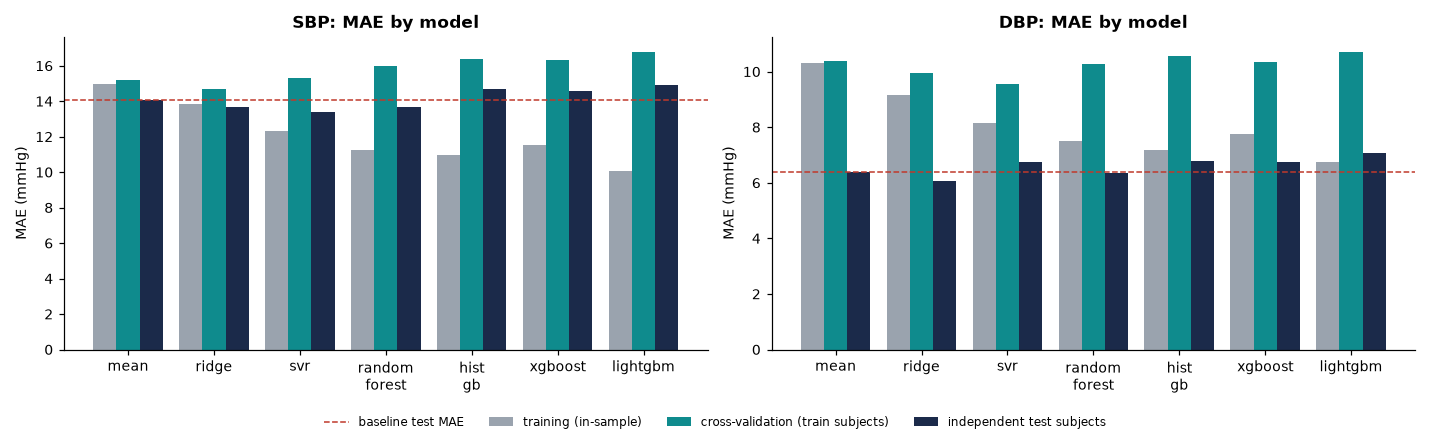

In [13]:
comp = result["comparison"]
display(comp[["target", "model", "params", "cv_mae", "train_mae", "test_mae", "test_rmse", "test_r2"]].round(3))
display(Image(R.plot_model_comparison(comp, OUT / "model_comparison.png")))

## 14. SBP prediction

In [14]:
sel_tab = result["selection"].set_index("target")
p = result["test_predictions"]
sbp = p[(p.target == "sbp") & (p.model == sel_tab.loc["sbp", "model"])]
print("selected SBP model:", sel_tab.loc["sbp", "label"], sel_tab.loc["sbp", "params"])
display(sbp.head())

selected SBP model: Ridge regression {'alpha': 10000.0}


,window_id,subject_id,session,activity,target,model,y,pred
1215,HC_12_1_w0110,auricle_HC_12,1,rest,sbp,ridge,133.70,108.312441
1216,HC_12_1_w0114,auricle_HC_12,1,rest,sbp,ridge,116.60,119.532926
1217,HC_12_1_w0129,auricle_HC_12,1,exercise,sbp,ridge,88.84,120.164218
1218,HC_12_1_w0149,auricle_HC_12,1,rest,sbp,ridge,146.69,122.875438
1219,HC_12_1_w0150,auricle_HC_12,1,rest,sbp,ridge,145.18,123.166697


## 15. DBP prediction

In [15]:
dbp = p[(p.target == "dbp") & (p.model == sel_tab.loc["dbp", "model"])]
print("selected DBP model:", sel_tab.loc["dbp", "label"], sel_tab.loc["dbp", "params"])
display(dbp.head())

selected DBP model: Support vector regression (RBF) {'C': 3.0, 'epsilon': 2.0, 'gamma': 0.01}


,window_id,subject_id,session,activity,target,model,y,pred
10935,HC_12_1_w0110,auricle_HC_12,1,rest,dbp,svr,61.14,74.069551
10936,HC_12_1_w0114,auricle_HC_12,1,rest,dbp,svr,55.05,68.291171
10937,HC_12_1_w0129,auricle_HC_12,1,exercise,dbp,svr,35.50,68.738224
10938,HC_12_1_w0149,auricle_HC_12,1,rest,dbp,svr,70.16,68.631009
10939,HC_12_1_w0150,auricle_HC_12,1,rest,dbp,svr,68.12,68.876535


## 16. Performance evaluation
Independent test subjects, cross-validation and cross-session results, and the comparison with the baseline.

In [16]:
summary = R.metrics_summary(result)
display(summary.round(2))
display(result["baseline_comparison"].round(3))
display(result["cross_session"].round(3))

,target,model,role,evaluation,mae,rmse,r2,bias,sd_error,loa_low,loa_high,n_windows,n_subjects
0,SBP,ridge,selected,training (in-sample),13.87,17.73,0.14,0.00,17.73,-34.75,34.75,4317,32
1,SBP,ridge,selected,cross-validation,14.69,18.63,0.07,-0.14,18.64,-36.67,36.39,3949,32
2,SBP,ridge,selected,independent test,13.66,16.26,-0.05,5.96,15.14,-23.70,35.63,1215,8
3,SBP,mean,baseline,training (in-sample),14.98,19.14,0.00,0.00,19.14,-37.52,37.52,4317,32
4,SBP,mean,baseline,cross-validation,15.18,19.32,-0.00,-0.00,19.32,-37.87,37.86,3949,32
5,SBP,mean,baseline,independent test,14.08,16.92,-0.14,5.87,15.88,-25.26,37.00,1215,8
6,SBP,mean,baseline,cross-session (train S1 → test subjects S2),12.91,14.68,-0.36,7.56,12.59,-17.12,32.25,473,6
7,SBP,ridge,selected,cross-session (train S1 → test subjects S2),12.32,14.21,-0.28,6.15,12.82,-18.98,31.28,473,6
8,DBP,svr,selected,training (in-sample),8.16,11.62,0.27,-1.38,11.54,-24.00,21.25,4317,32
9,DBP,svr,selected,cross-validation,9.55,13.09,0.06,-1.37,13.02,-26.89,24.14,3949,32


,target,model,mae_difference,ci_low,ci_high,model_better,baseline_better
0,sbp,ridge,-0.413,-1.731,1.006,False,False
1,dbp,svr,0.366,-1.311,1.870,False,False


,target,model,train,test,mae,rmse,r2,bias,sd_error,loa_low,loa_high,n_windows,n_subjects,subject_mean_mae
0,sbp,mean,"train subjects, session 1","test subjects, session 2",12.914,14.678,-0.361,7.563,12.593,-17.121,32.246,473,6,13.332
1,sbp,ridge,"train subjects, session 1","test subjects, session 2",12.321,14.206,-0.275,6.150,12.819,-18.975,31.276,473,6,13.489
2,dbp,mean,"train subjects, session 1","test subjects, session 2",6.166,7.236,-0.002,-0.352,7.235,-14.534,13.829,473,6,6.634
3,dbp,svr,"train subjects, session 1","test subjects, session 2",7.836,9.708,-0.804,-3.648,9.006,-21.301,14.004,473,6,8.339


## 17. Actual versus predicted

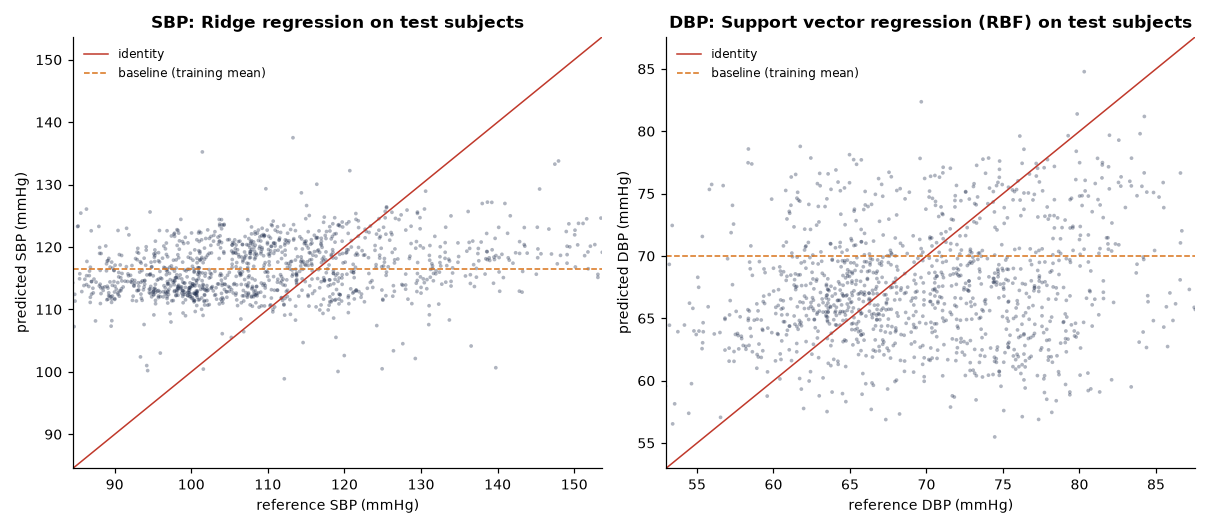

In [17]:
display(Image(R.plot_actual_vs_predicted(p, result["selection"], OUT / "actual_vs_predicted.png")))

## 18. Error distribution

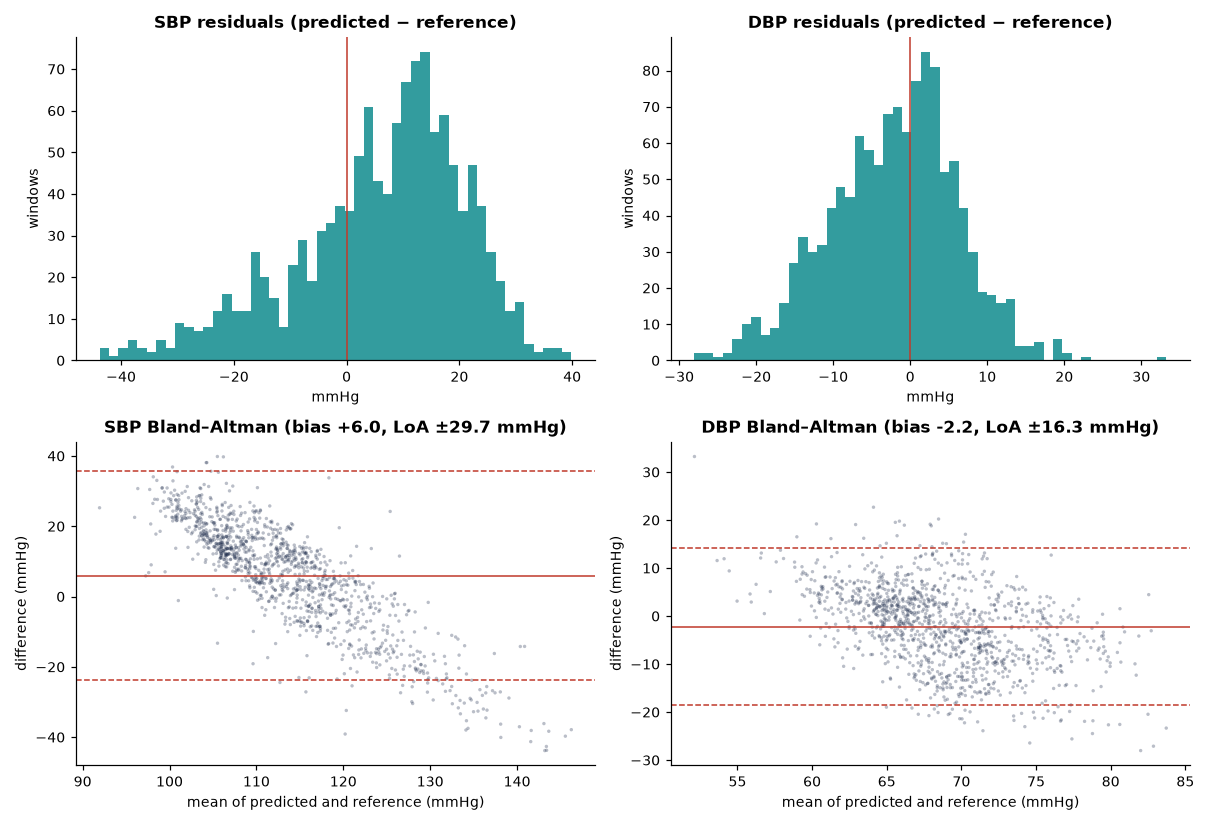

In [18]:
display(Image(R.plot_residuals(p, result["selection"], OUT / "residuals.png")))

## 19. Final model selection
The candidate with the lowest cross-validated MAE per target (the test set is not used for selection).

In [19]:
display(result["selection"].round(3))
for t in ("sbp", "dbp"):
    b = result["baseline_comparison"].set_index("target").loc[t]
    verdict = "beats" if b.model_better else ("is worse than" if b.baseline_better else "is not significantly different from")
    print(f"{t.upper()}: the selected model {verdict} the training-mean baseline "
          f"(MAE difference {b.mae_difference:+.2f} mmHg, 95 % CI [{b.ci_low:+.2f}, {b.ci_high:+.2f}])")

,target,model,label,params,cv_mae,test_mae,test_rmse,test_r2,halfwidth_90,test_coverage_90,beats_baseline_on_test
0,sbp,ridge,Ridge regression,{'alpha': 10000.0},14.695,13.663,16.261,-0.049,30.336,0.958,False
1,dbp,svr,Support vector regression (RBF),"{'C': 3.0, 'epsilon': 2.0, 'gamma': 0.01}",9.552,6.748,8.605,-0.231,21.123,0.981,False


SBP: the selected model is not significantly different from the training-mean baseline (MAE difference -0.41 mmHg, 95 % CI [-1.73, +1.01])
DBP: the selected model is not significantly different from the training-mean baseline (MAE difference +0.37 mmHg, 95 % CI [-1.31, +1.87])


## 20. Model export
Export to a temporary bundle, then check that it predicts exactly like the bundle the pipeline exported (`models/rakshpulse_ear_bp.joblib`).

In [20]:
import tempfile
bundle = export_bundle(result, version="notebook")
tmp = bundle.save(Path(tempfile.mkdtemp()) / "notebook_model.joblib")
shipped = load_bundle(paths.root / "models" / "rakshpulse_ear_bp.joblib")
test = d[d.subject_id.isin(test_s)]
X = test[shipped.features].to_numpy(float)
same = all(np.allclose(getattr(load_bundle(tmp), t).predict(X), getattr(shipped, t).predict(X)) for t in ("sbp", "dbp"))
print("notebook model == pipeline-exported model:", same)
print(json.dumps(shipped.contract["selected_models"], default=str))
print("modes:", {k: shipped.contract[k] for k in ("validated_for", "experimental_for", "demonstration_for")})

notebook model == pipeline-exported model: True
{"sbp": {"model": "ridge", "params": {"alpha": 10000.0}}, "dbp": {"model": "svr", "params": {"C": 3.0, "epsilon": 2.0, "gamma": 0.01}}}
modes: {'validated_for': [], 'experimental_for': ['auricle_earlobe'], 'demonstration_for': ['max30102', 'simulator']}


## 21. Example inference
The hardware-facing API (`rakshpulse.inference.api`) on 30 s of raw earlobe PPG from a test subject, as `auricle_earlobe` (the population the model was tested on) and as `max30102` (demonstration only). The Auricle signals are in mV, not ADC counts, so ADC rail checks are switched off with `ANALOG_INPUT`.

In [21]:
test_ids = set(d[d.subject_id.isin(test_s) & (d.session == 1)].window_id)
w1i = w1.reset_index()
start = None
for rec, g in w1i.groupby("record_id"):
    g = g.sort_values("t_start_s")
    ok = g[g.window_id.isin(test_ids)]
    for t0 in ok.t_start_s:
        chunk = g[g.t_start_s.isin([t0, t0 + 10, t0 + 20])]
        if len(chunk) == 3 and chunk.window_id.isin(test_ids).all():
            start = chunk
            break
    if start is not None:
        break
pos = {w: k for k, w in enumerate(ids)}
signal = np.concatenate([wav["raw_ear"][pos[w]].astype(float) for w in start.window_id])
ref = start[["sbp_mmHg", "dbp_mmHg"]].mean()
for sensor in ("auricle_earlobe", "max30102"):
    est = BPEstimator(sensor=sensor, pipeline_overrides=ANALOG_INPUT)
    r = est.estimate(signal, 100.0, metadata={"source": "Auricle test subject", "windows": list(start.window_id)})
    print(f"[{sensor}] status={r.status} SBP={r.sbp} DBP={r.dbp} interval={r.sbp_interval_90}/{r.dbp_interval_90} "
          f"mode={r.inference_mode} latency={r.latency_ms} ms")
    print("   quality:", r.signal_quality, "| warnings:", r.warnings)
print(f"CNAP reference over the same 30 s: SBP {ref.sbp_mmHg:.1f} / DBP {ref.dbp_mmHg:.1f} mmHg")

stream = StreamingBPEstimator(BPEstimator(sensor="auricle_earlobe", pipeline_overrides=ANALOG_INPUT), fs=100.0,
                              buffer_s=30, with_red=False)
for k in range(0, signal.size, 32):              # e.g. FIFO-sized chunks
    stream.push(signal[k:k + 32])
print("streaming:", stream.estimate().to_dict()["status"], f"after {stream.buffered_s:.0f} s buffered")
print("invalid input:", BPEstimator().estimate(signal[:300], 100.0).message)

[auricle_earlobe] status=ok SBP=118.3 DBP=67.1 interval=(88.0, 148.6)/(46.0, 88.2) mode=experimental latency=109.8 ms
   quality: {'windows_total': 5, 'windows_usable': 3, 'windows_degraded': 2, 'windows_unusable': 0, 'windows_missing': 0, 'windows_predicted': 5, 'median_quality_score': 100.0, 'reasons': {'margin:template_corr': 2, 'margin:rr_cv': 1}} | warnings: ['experimental model: cross-validated and tested on held-out subjects of its training population only; not a clinically validated measurement']
[max30102] status=ok SBP=118.3 DBP=67.1 interval=None/None mode=demonstration latency=105.4 ms
   quality: {'windows_total': 5, 'windows_usable': 3, 'windows_degraded': 2, 'windows_unusable': 0, 'windows_missing': 0, 'windows_predicted': 5, 'median_quality_score': 100.0, 'reasons': {'margin:template_corr': 2, 'margin:rr_cv': 1}} | warnings: ['DEMONSTRATION MODE: this model has not been validated for this sensor; the numbers show that the pipeline runs and are NOT blood-pressure measure

streaming: ok after 30 s buffered
invalid input: need at least 10 s of samples (1000 at 100 Hz), got 300
